In [ ]:
%load_ext autoreload
%autoreload 2
import torch
import torch.nn as nn
import os
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

import wandb

from copy import deepcopy

from cmcrameri import cm


# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

In [2]:
# set random seed
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(42)

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
from plot_utils import extract_all_results, results_to_dataframe, plot_comparison, \
    method_names, method_colors

In [ ]:
from repl.networks.utils import additional_data_process, prepare_model
from repl.scripts.utils import (
    get_data_specs,
    prepare_data,
)

from repl.networks.networks import LinearReadout

In [6]:
api = wandb.Api()

In [ ]:
savedir = '../RPL_figures/7_oddballs'
if not os.path.exists(savedir):
    os.makedirs(savedir)

In [ ]:
# Please download the data from the paper and set the path here
exp_data_dir = 'PATH_TO_EXPERIMENTAL_DATA_DIRECTORY/pfc_monkey_1_projections'

In [ ]:
datasets = ['oddballs']

dataset_to_plot = 'oddballs'
    
method_map = {
    'sup': 'supervised',
    'rand': 'random',
    'inv': 'inv',
    'hebb': 'inv_hebb',
    'pred': 'pred',
    'inv_sg': 'inv_sg',
    'pred-mem': 'pred_ctx_target',
    'pred-reg': 'pred_vcreg'
}

# Extract results with both accuracy and r2 metrics
results = extract_all_results(datasets=datasets, method_map=method_map, wandb_project="RPL")

# Convert to DataFrame
results_df = results_to_dataframe(results)

No exact match found for method_key: 
No exact match found for method_key: pred_longrun
No exact match found for method_key: 
No exact match found for method_key: 
No exact match found for method_key: full_short_seq_20_bn_large_pred
Processed 3 runs
Found accuracy metrics in 3 runs
Found R2 metrics in 0 runs


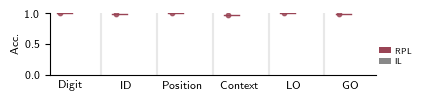

In [10]:
fig, axs = plot_comparison(results_df, 
                    methods_to_plot=['pred', 'inv_sg'],
                    baseline_methods=['sup', 'rand'],
                    task_names={'digit': 'Digit', 'identity': 'ID', 'serial_position': 'Position', 'global_context': 'Context',
                                'local_oddball': 'LO', 'global_oddball': 'GO'},
                    method_names=method_names,
                    method_colors=method_colors,
                    figsize=(4.2, 0.8),
                    dataset='oddballs',
                    ylim=(0.0, 1.0),
                    loc_legend=(1.0, 0.1),
                    display_legend=True,
                    legend_ax_idx=1,
                    point_size=10,
                    sharey=True)
fig.savefig(os.path.join(savedir, 'oddballs_comparison.pdf'), bbox_inches='tight', transparent=True)

In [11]:
input_size, num_classes = get_data_specs(dataset="oddballs",
                                        target_label="multitask",
                                        mnist_seqtype="local_global_oddball",
                                        flatten_images=True,)

(train_loader, train_sampler, 
    val_loader, val_sampler,
        test_loader, test_sampler,
    ) = prepare_data(
            dataset="oddballs",
            data_input_dir="../datasets",
            seq_len=128,
            batch_size=32,
            val_batch_size=32,
            grayscale=True,
            distributed=False,
            target_label="multitask",
            mnist_seqtype="local_global_oddball",
            num_sequences=2000,
            inter_trial_interval=4,
        )

In [ ]:
preprocess, postprocess = additional_data_process("mnist")
n_in_channels = 1

pred_model = deepcopy(prepare_model(
    encoder_kind="mlp",
    integrator_kind="lstm",
    predictor_kind="mlp",
    input_size=input_size,
    pred_n_hidden_layers=1,
    enc_dim=64,
    ctx_dim=256,
    prediction_target="enc",
    use_bn_enc=True,
    enc_n_layers=2,
    enc_kernel_size=[(3, 3)] * 2,
    enc_stride=[(1, 1)] * 2,
    enc_padding=[(1, 1)] * 2,
    preprocess=preprocess,
    postprocess=postprocess,
    n_in_channels=n_in_channels,
    pred_hidden_dim=256,
    pred_steps=1,
    dense_prediction=False,
    state_dict=torch.load('../checkpoints/oddballs_pred_1/model_final.pt')
)).to(device)

In [13]:
def prepare_readout(readout_input_dim, num_classes):
    readout = nn.ModuleList()
    num_classes_seq_labels = num_classes[0]
    if num_classes_seq_labels is not None:
        for task_name in num_classes_seq_labels.keys():
            readout.append(LinearReadout(num_classes=num_classes_seq_labels[task_name], input_dim=readout_input_dim,
                                            seq_len=32, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=False))
    num_classes_dense_labels = num_classes[1]
    if num_classes_dense_labels is not None:
        for task_name in num_classes_dense_labels.keys():
            readout.append(LinearReadout(num_classes=num_classes_dense_labels[task_name], input_dim=readout_input_dim,
                                            seq_len=32, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=True))
    num_seq_regr_targets = num_classes[2]
    if num_seq_regr_targets is not None:
        for task_name in num_seq_regr_targets.keys():
            readout.append(LinearReadout(num_classes=num_seq_regr_targets[task_name], input_dim=readout_input_dim,
                                            seq_len=32, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=False))
    num_dense_regr_targets = num_classes[3]
    if num_dense_regr_targets is not None:
        for task_name in num_dense_regr_targets.keys():
            readout.append(LinearReadout(num_classes=num_dense_regr_targets[task_name], input_dim=readout_input_dim,
                                            seq_len=32, concat_over_time=False, task_name=task_name,
                                            concat_over_batch=True))
    
    return readout

In [ ]:
readout_input_dim = pred_model.integrator.backbone.weight_ih_l0.shape[0] // 4

pred_readout = prepare_readout(readout_input_dim, num_classes=num_classes).to(device)

In [ ]:
pred_readout.load_state_dict(torch.load(os.path.join("../checkpoints/oddballs_pred_1/offline_ctx_readout.pt")))

<All keys matched successfully>

In [ ]:
pred_readout_stats = torch.load(os.path.join("../checkpoints/oddballs_pred_1/offline_ctx_readout_stats.pt"))

pred_mean, pred_std = pred_readout_stats['mean'], pred_readout_stats['std']

In [ ]:
block_len = 12

In [ ]:
# Set the models to evaluation mode, pass the validation data through the models, and record the outputs
pred_model.eval()

# train logistic regression readout for pred_model on train set and evaluate on test set
stim_id_readout = nn.Linear(readout_input_dim, 1).to(device)
context_readout = nn.Linear(readout_input_dim, 1).to(device)
context_avg_readout = nn.Linear(readout_input_dim, 1).to(device)
local_oddball_readout = nn.Linear(readout_input_dim, 1).to(device)
global_oddball_readout = nn.Linear(readout_input_dim, 1).to(device)
serial_position_readout = nn.Linear(readout_input_dim, 4).to(device)

# change to True if you have run the notebook once
load_readouts = False

if load_readouts:
    stim_id_readout.load_state_dict(torch.load(os.path.join(savedir, 'stim_id_readout.pt')))
    context_readout.load_state_dict(torch.load(os.path.join(savedir, 'context_readout.pt')))
    context_avg_readout.load_state_dict(torch.load(os.path.join(savedir, 'context_avg_readout.pt')))
    local_oddball_readout.load_state_dict(torch.load(os.path.join(savedir, 'local_oddball_readout.pt')))
    global_oddball_readout.load_state_dict(torch.load(os.path.join(savedir, 'global_oddball_readout.pt')))
    serial_position_readout.load_state_dict(torch.load(os.path.join(savedir, 'serial_position_readout.pt')))

else:
    stim_id_readout.train()
    context_readout.train()
    context_avg_readout.train()
    local_oddball_readout.train()
    global_oddball_readout.train()
    serial_position_readout.train()

    optimizer = torch.optim.AdamW(list(stim_id_readout.parameters()) +
                                list(context_readout.parameters()) +
                                list(context_avg_readout.parameters()) +
                                list(local_oddball_readout.parameters()) +
                                list(global_oddball_readout.parameters()) +
                                list(serial_position_readout.parameters()), lr=1e-3, weight_decay=1e-5)
    criterion = nn.BCEWithLogitsLoss()
    classifier_criterion = nn.CrossEntropyLoss(ignore_index=-1)
    num_epochs = 50
    best_val_loss = float('inf')
    best_stim_id_readout = deepcopy(stim_id_readout.state_dict())
    best_context_readout = deepcopy(context_readout.state_dict())
    best_context_avg_readout = deepcopy(context_avg_readout.state_dict())
    best_local_oddball_readout = deepcopy(local_oddball_readout.state_dict())
    best_global_oddball_readout = deepcopy(global_oddball_readout.state_dict())
    best_serial_position_readout = deepcopy(serial_position_readout.state_dict())
    patience = 10
    counter = 0

    for epoch in range(num_epochs):
        total_loss = 0.0
        for batch in train_loader:
            inputs, targets = batch
            inputs = inputs.to(device)
            targets = [t.to(device) for t in targets]
            targets = targets[1]

            with torch.no_grad():
                _, pred_ctx, _ = pred_model(inputs)
                # normalize
                pred_ctx = (pred_ctx - pred_mean) / pred_std
                pred_ctx = pred_ctx.detach()

                # take only the last 75% of the context representations in each block
                seq_len = pred_ctx.shape[1]
                start_idx = seq_len // 4
                pred_ctx = pred_ctx[:, start_idx:, :]
                targets = targets[:, start_idx:, :]

            stim_id_logits = stim_id_readout(pred_ctx).squeeze(-1)
            stim_labels = targets[:,:,1]
            mask = stim_labels != -1
            stim_id_logits = stim_id_logits[mask]
            stim_id_loss = criterion(stim_id_logits, stim_labels[mask].float())

            serial_position_logits = serial_position_readout(pred_ctx).squeeze(-1)
            serial_position_labels = targets[:, :, 2]
            mask = serial_position_labels != -1
            serial_position_logits = serial_position_logits[mask]
            # convert to binary classification for each position, still ignore -1 labels
            serial_position_loss = 0.0
            for i in range(4):
                pos_labels = serial_position_labels == i
                pos_logits = serial_position_logits[:, i]
                serial_position_loss += criterion(pos_logits, pos_labels[mask].float())
            # serial_position_loss = classifier_criterion(serial_position_logits, serial_position_labels[mask])

            context_logits = context_readout(pred_ctx).squeeze(-1)
            context_labels = targets[:,:,3]
            mask = context_labels != -1
            context_logits = context_logits[mask]
            context_loss = criterion(context_logits, context_labels[mask].float())

            # context requires special handling since we need to average over the first 6 stimuli in each sequence
            pred_ctx_ = pred_ctx.reshape(-1, block_len, pred_ctx.shape[-1])
            pred_ctx_ = pred_ctx_[:,:6,:].mean(dim=1)
            context_avg_logits = context_avg_readout(pred_ctx_).squeeze(-1) # [B]
            context_avg_labels = targets[:,4::block_len,3].reshape(-1)
            mask = context_avg_labels != -1
            context_avg_logits = context_avg_logits[mask]
            context_avg_loss = criterion(context_avg_logits, context_avg_labels[mask].float())

            local_oddball_logits = local_oddball_readout(pred_ctx).squeeze(-1)
            local_oddball_labels = targets[:, :, 4]
            mask = local_oddball_labels != -1
            local_oddball_logits = local_oddball_logits[mask]
            local_oddball_loss = criterion(local_oddball_logits, local_oddball_labels[mask].float())

            global_oddball_logits = global_oddball_readout(pred_ctx).squeeze(-1)
            global_oddball_labels = targets[:, :, 5]
            mask = global_oddball_labels != -1
            global_oddball_logits = global_oddball_logits[mask]
            global_oddball_loss = criterion(global_oddball_logits, global_oddball_labels[mask].float())

            loss = stim_id_loss + context_loss + context_avg_loss + local_oddball_loss + global_oddball_loss + serial_position_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * inputs.size(0)
        avg_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {avg_loss:.4f}")
        # evaluate on val set
        val_accs = {'stim_id': 0.0, 'context': 0.0, 'context_avg': 0.0, 'local_oddball': 0.0, 'global_oddball': 0.0, 'serial_position': 0.0}
        val_counts = {'stim_id': 0, 'context': 0, 'context_avg': 0, 'local_oddball': 0, 'global_oddball': 0, 'serial_position': 0}
        val_loss = 0.0
        with torch.no_grad():
            for batch in test_loader:
                inputs, targets = batch
                inputs = inputs.to(device)
                targets = [t.to(device) for t in targets]
                targets = targets[1]

                _, pred_ctx, _ = pred_model(inputs)
                # normalize
                pred_ctx = (pred_ctx - pred_mean) / pred_std

                stim_id_logits = stim_id_readout(pred_ctx).squeeze(-1)
                stim_id_labels = targets[:,:,1]
                mask = stim_id_labels != -1
                stim_id_logits = stim_id_logits[mask]
                stim_id_loss = criterion(stim_id_logits, stim_id_labels[mask].float())
                stim_id_preds = (torch.sigmoid(stim_id_logits) > 0.5).long()
                val_accs['stim_id'] += (stim_id_preds == stim_id_labels[mask]).sum().item()
                val_counts['stim_id'] += mask.sum().item()

                serial_position_logits = serial_position_readout(pred_ctx).squeeze(-1)
                serial_position_labels = targets[:, :, 2]
                mask = serial_position_labels != -1
                serial_position_logits = serial_position_logits[mask]
                serial_position_loss = classifier_criterion(serial_position_logits, serial_position_labels[mask])
                serial_position_preds = serial_position_logits.argmax(dim=-1)
                val_accs['serial_position'] += (serial_position_preds == serial_position_labels[mask]).sum().item()
                val_counts['serial_position'] += mask.sum().item()

                context_logits = context_readout(pred_ctx).squeeze(-1)
                context_labels = targets[:,:,3]
                mask = context_labels != -1
                context_logits = context_logits[mask]
                context_loss = criterion(context_logits, context_labels[mask].float())
                context_preds = (torch.sigmoid(context_logits) > 0.5).long()
                val_accs['context'] += (context_preds == context_labels[mask]).sum().item()
                val_counts['context'] += mask.sum().item()

                context_avg_logits = context_avg_readout(pred_ctx).squeeze(-1)
                context_avg_labels = targets[:,:,3]
                mask = context_avg_labels != -1
                context_avg_logits = context_avg_logits[mask]
                context_avg_loss = criterion(context_avg_logits, context_avg_labels[mask].float())
                context_avg_preds = (torch.sigmoid(context_avg_logits) > 0.5).long()
                val_accs['context_avg'] += (context_avg_preds == context_avg_labels[mask]).sum().item()
                val_counts['context_avg'] += mask.sum().item()

                local_oddball_logits = local_oddball_readout(pred_ctx).squeeze(-1)
                local_oddball_labels = targets[:,:,4]
                mask = local_oddball_labels != -1
                local_oddball_logits = local_oddball_logits[mask]
                local_oddball_loss = criterion(local_oddball_logits, local_oddball_labels[mask].float())
                local_oddball_preds = (torch.sigmoid(local_oddball_logits) > 0.5).long()
                val_accs['local_oddball'] += (local_oddball_preds == local_oddball_labels[mask]).sum().item()
                val_counts['local_oddball'] += mask.sum().item()

                global_oddball_logits = global_oddball_readout(pred_ctx).squeeze(-1)
                global_oddball_labels = targets[:,:,5]
                mask = global_oddball_labels != -1
                global_oddball_logits = global_oddball_logits[mask]
                global_oddball_loss = criterion(global_oddball_logits, global_oddball_labels[mask].float())
                global_oddball_preds = (torch.sigmoid(global_oddball_logits) > 0.5).long()
                val_accs['global_oddball'] += (global_oddball_preds == global_oddball_labels[mask]).sum().item()
                val_counts['global_oddball'] += mask.sum().item()
                val_loss += stim_id_loss.item() + context_loss.item() + context_avg_loss.item() + local_oddball_loss.item() + global_oddball_loss.item()
            avg_val_loss = val_loss / len(val_loader.dataset)
            print(f"Epoch {epoch+1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}, "
                f"Stim ID Acc: {val_accs['stim_id']/val_counts['stim_id']:.4f}, "
                f"Context Acc: {val_accs['context']/val_counts['context']:.4f}, "
                f"Context Avg Acc: {val_accs['context_avg']/val_counts['context_avg']:.4f}, "
                f"Serial Position Acc: {val_accs['serial_position']/val_counts['serial_position']:.4f}, "
                f"Local Oddball Acc: {val_accs['local_oddball']/val_counts['local_oddball']:.4f}, "
                f"Global Oddball Acc: {val_accs['global_oddball']/val_counts['global_oddball']:.4f}")
            # early stopping
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                best_stim_id_readout = deepcopy(stim_id_readout.state_dict())
                best_context_readout = deepcopy(context_readout.state_dict())
                best_context_avg_readout = deepcopy(context_avg_readout.state_dict())
                best_local_oddball_readout = deepcopy(local_oddball_readout.state_dict())
                best_global_oddball_readout = deepcopy(global_oddball_readout.state_dict())
                best_serial_position_readout = deepcopy(serial_position_readout.state_dict())
                counter = 0
            else:
                counter += 1
                if counter >= patience:
                    print("Early stopping would have triggered here")
                    # break
    # load best model
    stim_id_readout.load_state_dict(best_stim_id_readout)
    context_readout.load_state_dict(best_context_readout)
    context_avg_readout.load_state_dict(best_context_avg_readout)
    local_oddball_readout.load_state_dict(best_local_oddball_readout)
    global_oddball_readout.load_state_dict(best_global_oddball_readout)
    serial_position_readout.load_state_dict(best_serial_position_readout)

    # save the readouts
    torch.save(stim_id_readout.state_dict(), os.path.join(savedir, 'stim_id_readout.pt'))
    torch.save(context_readout.state_dict(), os.path.join(savedir, 'context_readout.pt'))
    torch.save(context_avg_readout.state_dict(), os.path.join(savedir, 'context_avg_readout.pt'))
    torch.save(local_oddball_readout.state_dict(), os.path.join(savedir, 'local_oddball_readout.pt'))
    torch.save(global_oddball_readout.state_dict(), os.path.join(savedir, 'global_oddball_readout.pt'))
    torch.save(serial_position_readout.state_dict(), os.path.join(savedir, 'serial_position_readout.pt'))

In [ ]:
pred_ctxs = []
pred_zs = []
pred_readout_logits = [[] for _ in range(len(pred_readout))]
pred_avg_readout_logits = [[] for _ in range(len(pred_readout))]

labels = []

for i, (data, target) in enumerate(test_loader):
    data = data.to(device)
    target = [t.to(device) for t in target]
    labels.append(target[1])

    z, proj, _ = pred_model(data)
    pred_readout_input = (proj - pred_mean) / pred_std

    seq_len = pred_readout_input.shape[1]

    for j in range(len(pred_readout)):
        if j not in [1, 3, 4, 5]:
            pred_logits = pred_readout[j](pred_readout_input)
            pred_logits = pred_logits.detach().view(-1, seq_len, pred_logits.size(-1))
        else:
            # use the newly trained readouts
            if j == 1:
                pred_logits = stim_id_readout(pred_readout_input)
            elif j == 3:
                pred_logits = context_readout(pred_readout_input)
                pred_avg_logits = context_avg_readout(pred_readout_input)
            elif j == 4:
                pred_logits = local_oddball_readout(pred_readout_input)
            elif j == 5:
                pred_logits = global_oddball_readout(pred_readout_input)
        pred_readout_logits[j].append(pred_logits)
        pred_avg_readout_logits[j].append(pred_avg_logits) if j == 3 else []


    if i >= 10:
        break

pred_readout_logits = [torch.cat(logits, dim=0) for logits in pred_readout_logits]
pred_avg_readout_logits = [torch.cat(logits, dim=0) for logits in pred_avg_readout_logits if len(logits) > 0]

labels = torch.cat(labels, dim=0)

In [ ]:
seq_len = labels.size(1)
start_idx = seq_len // 4

pred_readout_logits = [logits[:, start_idx:].reshape(-1, block_len, logits.size(-1)) for logits in pred_readout_logits]
pred_avg_readout_logits = [logits[:, start_idx:].reshape(-1, block_len, logits.size(-1)) for logits in pred_avg_readout_logits if len(logits) > 0]

labels = labels[:, start_idx:].reshape(-1, block_len, labels.size(-1))

In [ ]:
# apply sigmoid for binary classification
pred_readout_probs = [nn.functional.sigmoid(logits) for logits in pred_readout_logits]
pred_avg_readout_probs = [nn.functional.sigmoid(logits) for logits in pred_avg_readout_logits if len(logits) > 0]

In [22]:
labels[40, :, 2]

tensor([ 0, -1,  1, -1,  2, -1,  3, -1, -1, -1, -1, -1], device='cuda:0')

In [23]:
subsampled_labels = labels[:, :8:2] # shape [N, 4, 6]
lab = subsampled_labels[:, :, 1]

aaaa_mask = (lab[:, 0] == 0) & (lab[:, 1] == 0) & (lab[:, 2] == 0) & (lab[:, 3] == 0)
aaab_mask = (lab[:, 0] == 0) & (lab[:, 1] == 0) & (lab[:, 2] == 0) & (lab[:, 3] == 1)
bbbb_mask = (lab[:, 0] == 1) & (lab[:, 1] == 1) & (lab[:, 2] == 1) & (lab[:, 3] == 1)
bbba_mask = (lab[:, 0] == 1) & (lab[:, 1] == 1) & (lab[:, 2] == 1) & (lab[:, 3] == 0)

aaaa_idxes = torch.where(aaaa_mask)[0]
aaab_idxes = torch.where(aaab_mask)[0]
bbbb_idxes = torch.where(bbbb_mask)[0]
bbba_idxes = torch.where(bbba_mask)[0]

print(f"AAAA count: {aaaa_idxes.size(0)}")
print(f"AAAB count: {aaab_idxes.size(0)}")
print(f"BBBB count: {bbbb_idxes.size(0)}")
print(f"BBBA count: {bbba_idxes.size(0)}")

AAAA count: 1345
AAAB count: 1160
BBBB count: 1488
BBBA count: 1287


In [24]:
lab_local = subsampled_labels[:, 3, 4]
lab_global = subsampled_labels[:, 3, 5]

xxxx = torch.where((lab_local == 0) & (lab_global == 0))
xxxy = torch.where((lab_local == 0) & (lab_global == 1))
xyxy = torch.where((lab_local == 1) & (lab_global == 0))
xyxx = torch.where((lab_local == 1) & (lab_global == 1))

print(f"XXXX count: {xxxx[0].size(0)}")
print(f"XXXY count: {xxxy[0].size(0)}")
print(f"XYXY count: {xyxy[0].size(0)}")
print(f"XYXX count: {xyxx[0].size(0)}")

XXXX count: 2329
XXXY count: 504
XYXY count: 1866
XYXX count: 581


In [25]:
local_standard_idxes = torch.where(lab_local == 0)[0]
local_oddball_idxes = torch.where(lab_local == 1)[0]

global_standard_idxes = torch.where(lab_global == 0)[0]
global_oddball_idxes = torch.where(lab_global == 1)[0]

print(f"Local Standard count: {local_standard_idxes.size(0)}")
print(f"Local Oddball count: {local_oddball_idxes.size(0)}")
print(f"Global Standard count: {global_standard_idxes.size(0)}")
print(f"Global Oddball count: {global_oddball_idxes.size(0)}")

Local Standard count: 2833
Local Oddball count: 2447
Global Standard count: 4195
Global Oddball count: 1085


In [26]:
# rows where previous stimulus was frequent and not oddball (resets every 15 stimuli)
xx_after_frequent = torch.zeros_like(lab_local).bool()
xy_after_frequent = torch.zeros_like(lab_local).bool()
xx_after_rare = torch.zeros_like(lab_local).bool()
xy_after_rare = torch.zeros_like(lab_local).bool()
for i in range(subsampled_labels.size(0)):
    if i % 15 == 0:
        continue
    if lab_global[i-1] == 0:
        if lab_local[i] == 0:
            xx_after_frequent[i] = True
        else:
            xy_after_frequent[i] = True
    elif lab_global[i-1] == 1:
        if lab_local[i] == 0:
            xx_after_rare[i] = True
        else:
            xy_after_rare[i] = True

print(f"XX after frequent count: {xx_after_frequent.sum().item()}")
print(f"XY after frequent count: {xy_after_frequent.sum().item()}")
print(f"XX after rare count: {xx_after_rare.sum().item()}")
print(f"XY after rare count: {xy_after_rare.sum().item()}")

XX after frequent count: 2112
XY after frequent count: 1817
XX after rare count: 530
XY after rare count: 469


# Stim ID

## Load experimental data

In [60]:
exp_aaaa_means = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_standard_standard_classical_600.npy'))
exp_aaaa_sems = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_standard_standard_classical_600_sem.npy'))

exp_bbba_means = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_standard_deviant_classical_600.npy'))
exp_bbba_sems = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_standard_deviant_classical_600_sem.npy'))

exp_aaab_means = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_deviant_deviant_classical_600.npy'))
exp_aaab_sems = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_deviant_deviant_classical_600_sem.npy'))

exp_bbbb_means = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_deviant_standard_classical_600.npy'))
exp_bbbb_sems = np.load(os.path.join(exp_data_dir, 'Proj_Stimulus_first3_deviant_standard_classical_600_sem.npy'))

time_points = np.load(os.path.join(exp_data_dir, 'time_bins_seq.npy'))

In [61]:
len(time_points)

132

## Plots

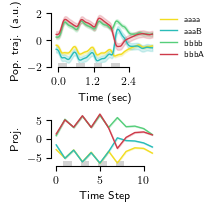

In [62]:
fig, axs = plt.subplots(2, 1, figsize=(2.05,2.0), constrained_layout=True)

plot_labels = ['aaaa', 'aaaB', 'bbbb', 'bbbA']
colors = {'aaaa': '#f2dd20',
          'aaaB': '#2abcb8',
          'bbbb': '#55ce7a',
          'bbbA': '#ce3a49'}

axs[0].plot(time_points, exp_aaaa_means, label='aaaa', color=colors['aaaa'], linewidth=1)
axs[0].fill_between(time_points, exp_aaaa_means - exp_aaaa_sems, exp_aaaa_means + exp_aaaa_sems, alpha=0.2, color=colors['aaaa'])
axs[0].plot(time_points, exp_aaab_means, label='aaaB', color=colors['aaaB'], linewidth=1)
axs[0].fill_between(time_points, exp_aaab_means - exp_aaab_sems, exp_aaab_means + exp_aaab_sems, alpha=0.2, color=colors['aaaB'])
axs[0].plot(time_points, exp_bbbb_means, label='bbbb', color=colors['bbbb'], linewidth=1)
axs[0].fill_between(time_points, exp_bbbb_means - exp_bbbb_sems, exp_bbbb_means + exp_bbbb_sems, alpha=0.2, color=colors['bbbb'])
axs[0].plot(time_points, exp_bbba_means, label='bbbA', color=colors['bbbA'], linewidth=1)
axs[0].fill_between(time_points, exp_bbba_means - exp_bbba_sems, exp_bbba_means + exp_bbba_sems, alpha=0.2, color=colors['bbbA'])

for i, idxes in enumerate([aaaa_idxes, aaab_idxes, bbbb_idxes, bbba_idxes]):
    logits = pred_readout_logits[1][idxes]
    logits_diff = logits  # prob of B - prob of A
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    axs[1].plot(mean, label=plot_labels[i], color=colors[plot_labels[i]], lw=1)
    axs[1].fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

axs[0].set_xlabel('Time (sec)', fontsize=8)
axs[0].set_ylabel('Pop. traj. (a.u.)', fontsize=8)
axs[0].set_yticks([-2, 0, 2])
axs[0].set_xticks([0, 1.2, 2.4])

axs[1].set_xlabel('Time Step', fontsize=8)
axs[1].set_ylabel('Proj.', fontsize=8)

soa = 0.6  # in sec
# add little gray boxes at 0, 0.6, 1.2, 1.8 above the axis line
for x in [0, 1, 2, 3]:
    axs[0].add_patch(plt.Rectangle(
        (x * soa, axs[0].get_ylim()[0] + 0.0 * np.ptp(axs[0].get_ylim())),  # bottom just above axis
        0.3,  # width
        0.08 * np.ptp(axs[0].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[0].transData,
        clip_on=False
    ))

# add little gray boxes at 2,4,6,8 above the axis line
for x in [1, 3, 5, 7]:
    axs[1].add_patch(plt.Rectangle(
        (x - 0.2, axs[1].get_ylim()[0] + 0.0 * np.ptp(axs[1].get_ylim())),  # bottom just above axis
        1.0,  # width
        0.09 * np.ptp(axs[1].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[1].transData,
        clip_on=False
    ))

sns.despine(trim=True)

axs[0].legend(fontsize=6, loc=(1.0, 0.1), frameon=False)

plt.savefig(os.path.join(savedir, 'oddballs_exp_vs_model_proj_stim_id.pdf'), bbox_inches='tight', transparent=True)

# Serial position

## Load experimental data

In [63]:
exp_item_0_xxxx_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item0_classical_600_first3.npy'))
exp_item_0_xxxx_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item0_sem_classical_600_first3.npy'))
exp_item_0_xxxY_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item0_classical_600_first3.npy'))
exp_item_0_xxxY_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item0_sem_classical_600_first3.npy'))

exp_item_1_xxxx_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item1_classical_600_first3.npy'))
exp_item_1_xxxx_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item1_sem_classical_600_first3.npy'))
exp_item_1_xxxY_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item1_classical_600_first3.npy'))
exp_item_1_xxxY_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item1_sem_classical_600_first3.npy'))

exp_item_2_xxxx_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item2_classical_600_first3.npy'))
exp_item_2_xxxx_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item2_sem_classical_600_first3.npy'))
exp_item_2_xxxY_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item2_classical_600_first3.npy'))
exp_item_2_xxxY_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item2_sem_classical_600_first3.npy'))

exp_item_3_xxxx_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item3_classical_600_first3.npy'))
exp_item_3_xxxx_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxx_item3_sem_classical_600_first3.npy'))
exp_item_3_xxxY_probs = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item3_classical_600_first3.npy'))
exp_item_3_xxxY_sems = np.load(os.path.join(exp_data_dir, 'ItemNumber_Proba_xxxY_item3_sem_classical_600_first3.npy'))

time_points = np.load(os.path.join(exp_data_dir, 'time_bins_item_number.npy'))

/tmp/ipykernel_348858/3059811154.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl_cm.get_cmap('YlGnBu')


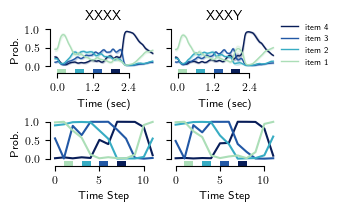

In [ ]:
import matplotlib.cm as mpl_cm

cmap = mpl_cm.get_cmap('YlGnBu')
item_colors = cmap(np.linspace(0.3,1,4))

fig, axs = plt.subplots(2, 2, figsize=(3.3, 2.0), constrained_layout=True, sharey=True)

# plot exp data
axs[0][0].plot(time_points, exp_item_3_xxxx_probs, label='item 4', color=item_colors[3], linewidth=1)
axs[0][0].fill_between(time_points, exp_item_3_xxxx_probs - exp_item_3_xxxx_sems, exp_item_3_xxxx_probs + exp_item_3_xxxx_sems, alpha=0.2, color=item_colors[3])
axs[0][0].plot(time_points, exp_item_2_xxxx_probs, label='item 3', color=item_colors[2], linewidth=1)
axs[0][0].fill_between(time_points, exp_item_2_xxxx_probs - exp_item_2_xxxx_sems, exp_item_2_xxxx_probs + exp_item_2_xxxx_sems, alpha=0.2, color=item_colors[2])
axs[0][0].plot(time_points, exp_item_1_xxxx_probs, label='item 2', color=item_colors[1], linewidth=1)
axs[0][0].fill_between(time_points, exp_item_1_xxxx_probs - exp_item_1_xxxx_sems, exp_item_1_xxxx_probs + exp_item_1_xxxx_sems, alpha=0.2, color=item_colors[1])
axs[0][0].plot(time_points, exp_item_0_xxxx_probs, label='item 1', color=item_colors[0], linewidth=1)
axs[0][0].fill_between(time_points, exp_item_0_xxxx_probs - exp_item_0_xxxx_sems, exp_item_0_xxxx_probs + exp_item_0_xxxx_sems, alpha=0.2, color=item_colors[0])

axs[0][1].plot(time_points, exp_item_3_xxxY_probs, label='item 4', color=item_colors[3], linewidth=1)
axs[0][1].fill_between(time_points, exp_item_3_xxxY_probs - exp_item_3_xxxY_sems, exp_item_3_xxxY_probs + exp_item_3_xxxY_sems, alpha=0.2, color=item_colors[3])
axs[0][1].plot(time_points, exp_item_2_xxxY_probs, label='item 3', color=item_colors[2], linewidth=1)
axs[0][1].fill_between(time_points, exp_item_2_xxxY_probs - exp_item_2_xxxY_sems, exp_item_2_xxxY_probs + exp_item_2_xxxY_sems, alpha=0.2, color=item_colors[2])
axs[0][1].plot(time_points, exp_item_1_xxxY_probs, label='item 2', color=item_colors[1], linewidth=1)
axs[0][1].fill_between(time_points, exp_item_1_xxxY_probs - exp_item_1_xxxY_sems, exp_item_1_xxxY_probs + exp_item_1_xxxY_sems, alpha=0.2, color=item_colors[1])
axs[0][1].plot(time_points, exp_item_0_xxxY_probs, label='item 1', color=item_colors[0], linewidth=1)
axs[0][1].fill_between(time_points, exp_item_0_xxxY_probs - exp_item_0_xxxY_sems, exp_item_0_xxxY_probs + exp_item_0_xxxY_sems, alpha=0.2, color=item_colors[0])

# set y limits to -0.2 to 1.0
axs[0][0].set_ylim([-0.2, 1.05])

# add little colored boxes at 0, 0.6, 1.2, 1.8 above the axis line for the left column
soa = 0.6  # in sec
for ax in [axs[0][0], axs[0][1]]:
    for x, i in enumerate([0, 1, 2, 3]):
        ax.add_patch(plt.Rectangle(
            (x * soa, ax.get_ylim()[0] + 0.0 * np.ptp(ax.get_ylim())),  # bottom just above axis
            0.3,  # width
            0.1 * np.ptp(ax.get_ylim()),  # height
            facecolor=item_colors[i],
            transform=ax.transData,
            clip_on=False
        ))

for i, idxes in enumerate([local_standard_idxes, local_oddball_idxes]):
    probs = pred_readout_probs[2][idxes]
    for j in range(probs.shape[-1]-1, -1, -1):  # for each item
        mean = probs[:, :, j].mean(0).detach().cpu().numpy()
        # roll last element to front for better visualization
        mean = np.roll(mean, 1)
        axs[1][i].plot(mean, label=f'item {j+1}', color=item_colors[j])
        # axs[i][1].set_title('XXXX' if i == 0 else 'XXXY', fontsize=10)

# add little colored boxes at 2,4,6,8 above the axis line for the bottom row
for ax in [axs[1][0], axs[1][1]]:
    for x, i in enumerate([0, 1, 2, 3]):
        ax.add_patch(plt.Rectangle(
            (x * 2 + 1, ax.get_ylim()[0] + 0.0 * np.ptp(ax.get_ylim())),  # bottom just above axis
            1.0,  # width
            0.1 * np.ptp(ax.get_ylim()),  # height
            facecolor=item_colors[i],
            transform=ax.transData,
            clip_on=False
        ))

# Add labels and legend
axs[1][0].set_xlabel('Time Step', fontsize=8)
axs[1][1].set_xlabel('Time Step', fontsize=8)
axs[0][0].set_xlabel('Time (sec)', fontsize=8)
axs[0][1].set_xlabel('Time (sec)', fontsize=8)
axs[0][0].set_ylabel('Prob.', fontsize=8)
axs[1][0].set_ylabel('Prob.', fontsize=8)
axs[0][1].legend(fontsize=6, frameon=False, loc=(1.0,0.1))

axs[0][0].set_title('XXXX', fontsize=10)
axs[0][1].set_title('XXXY', fontsize=10)

axs[0][0].set_xticks([0, 1.2, 2.4])
axs[0][1].set_xticks([0, 1.2, 2.4])

sns.despine(trim=True)

plt.savefig(os.path.join(savedir, 'oddballs_exp_vs_model_item_number_readout.pdf'), bbox_inches='tight', transparent=True)

# Global context

## Load experimental data

In [65]:
exp_xxxx_ctx_means = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_standard_standard_classical_600.npy'))
exp_xxxx_ctx_sems = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_standard_standard_classical_600_sem.npy'))

exp_xxxY_ctx_means = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_standard_deviant_classical_600.npy'))
exp_xxxY_ctx_sems = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_standard_deviant_classical_600_sem.npy'))

exp_xYxY_ctx_means = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_deviant_standard_classical_600.npy'))
exp_xYxY_ctx_sems = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_deviant_standard_classical_600_sem.npy'))

exp_xYxx_ctx_means = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_deviant_deviant_classical_600.npy'))
exp_xYxx_ctx_sems = np.load(os.path.join(exp_data_dir, 'Proj_Blocktype_first3_deviant_deviant_classical_600_sem.npy'))

time_points = np.load(os.path.join(exp_data_dir, 'time_bins_seq.npy'))

## Plots

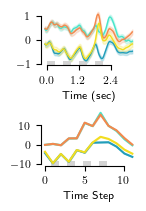

In [ ]:
# context
# Create a figure and axis
fig, axs = plt.subplots(2, 1, figsize=(1.35,2.0), constrained_layout=True)

plot_labels = ['xx|xx', 'xx|xY', 'xY|xY', 'xY|xx']
colors = {'xx|xx': '#229eba',
          'xx|xY': '#48e5ca',
          'xY|xY': '#f4884d',
          'xY|xx': '#f2dd20'}
label_str = {'xx|xx': r'xx$\mid$xx', 'xx|xY': r'xx$\mid$xY', 'xY|xY': r'xY$\mid$xY', 'xY|xx': r'xY$\mid$xx'}

axs[0].plot(time_points, exp_xxxx_ctx_means, label=label_str['xx|xx'], color=colors['xx|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxx_ctx_means - exp_xxxx_ctx_sems, exp_xxxx_ctx_means + exp_xxxx_ctx_sems, alpha=0.2, color=colors['xx|xx'])
axs[0].plot(time_points, exp_xxxY_ctx_means, label=label_str['xx|xY'], color=colors['xx|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxY_ctx_means - exp_xxxY_ctx_sems, exp_xxxY_ctx_means + exp_xxxY_ctx_sems, alpha=0.2, color=colors['xx|xY'])
axs[0].plot(time_points, exp_xYxY_ctx_means, label=label_str['xY|xY'], color=colors['xY|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxY_ctx_means - exp_xYxY_ctx_sems, exp_xYxY_ctx_means + exp_xYxY_ctx_sems, alpha=0.2, color=colors['xY|xY'])
axs[0].plot(time_points, exp_xYxx_ctx_means, label=label_str['xY|xx'], color=colors['xY|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxx_ctx_means - exp_xYxx_ctx_sems, exp_xYxx_ctx_means + exp_xYxx_ctx_sems, alpha=0.2, color=colors['xY|xx'])

soa = 0.6  # in sec
# add little gray boxes at 0, 0.6, 1.2, 1.8 above the axis line
for x in [0, 1, 2, 3]:
    axs[0].add_patch(plt.Rectangle(
        (x * soa, axs[0].get_ylim()[0] + 0.0 * np.ptp(axs[0].get_ylim())),  # bottom just above axis
        0.3,  # width
        0.08 * np.ptp(axs[0].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[0].transData,
        clip_on=False
    ))

axs[0].set_xticks([0, 1.2, 2.4])
axs[0].set_xlabel('Time (sec)', fontsize=8)

for i, idxes in enumerate([xxxx, xxxy, xyxy, xyxx]):
    logits = pred_avg_readout_logits[0][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes[0]))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    axs[1].plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    axs[1].fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

# add little gray boxes at 2,4,6,8 above the axis line
for x in [1, 3, 5, 7]:
    axs[1].add_patch(plt.Rectangle(
        (x - 0.2, axs[1].get_ylim()[0] + 0.0 * np.ptp(axs[1].get_ylim())),  # bottom just above axis
        1.0,  # width
        0.09 * np.ptp(axs[1].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[1].transData,
        clip_on=False
    ))

axs[1].set_xlabel('Time Step', fontsize=8)

sns.despine(trim=True)

plt.savefig(os.path.join(savedir, 'oddballs_exp_vs_model_proj_context_readout.pdf'), bbox_inches='tight', transparent=True)

# Local oddballs

## Load experimental data

In [67]:
exp_xxxx_local_means = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_standard_standard_classical_600.npy'))
exp_xxxx_local_sems = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_standard_standard_classical_600_sem.npy'))

exp_xxxY_local_means = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_standard_deviant_classical_600.npy'))
exp_xxxY_local_sems = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_standard_deviant_classical_600_sem.npy'))

exp_xYxY_local_means = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_deviant_standard_classical_600.npy'))
exp_xYxY_local_sems = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_deviant_standard_classical_600_sem.npy'))

exp_xYxx_local_means = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_deviant_deviant_classical_600.npy'))
exp_xYxx_local_sems = np.load(os.path.join(exp_data_dir, 'Proj_Local_last_deviant_deviant_classical_600_sem.npy'))

time_points = np.load(os.path.join(exp_data_dir, 'time_bins_local_global.npy'))

## Plots

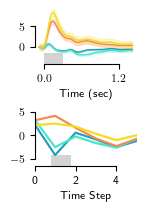

In [ ]:
# context
# Create a figure and axis
fig, axs = plt.subplots(2, 1, figsize=(1.35,2.0), constrained_layout=True)

plot_labels = ['xx|xx', 'xx|xY', 'xY|xY', 'xY|xx']
colors = {'xx|xx': '#229eba',
          'xx|xY': '#48e5ca',
          'xY|xY': '#f4884d',
          'xY|xx': '#f2dd20'}
label_str = {'xx|xx': r'xx$\mid$xx', 'xx|xY': r'xx$\mid$xY', 'xY|xY': r'xY$\mid$xY', 'xY|xx': r'xY$\mid$xx'}

axs[0].plot(time_points, exp_xxxx_local_means, label=label_str['xx|xx'], color=colors['xx|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxx_local_means - exp_xxxx_local_sems, exp_xxxx_local_means + exp_xxxx_local_sems, alpha=0.2, color=colors['xx|xx'])
axs[0].plot(time_points, exp_xxxY_local_means, label=label_str['xx|xY'], color=colors['xx|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxY_local_means - exp_xxxY_local_sems, exp_xxxY_local_means + exp_xxxY_local_sems, alpha=0.2, color=colors['xx|xY'])
axs[0].plot(time_points, exp_xYxY_local_means, label=label_str['xY|xY'], color=colors['xY|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxY_local_means - exp_xYxY_local_sems, exp_xYxY_local_means + exp_xYxY_local_sems, alpha=0.2, color=colors['xY|xY'])
axs[0].plot(time_points, exp_xYxx_local_means, label=label_str['xY|xx'], color=colors['xY|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxx_local_means - exp_xYxx_local_sems, exp_xYxx_local_means + exp_xYxx_local_sems, alpha=0.2, color=colors['xY|xx'])


axs[0].set_ylim([-4, 9])

soa = 0.6  # in sec
# add little gray boxes at 0, 0.6, 1.2, 1.8 above the axis line
for x in [0]:
    axs[0].add_patch(plt.Rectangle(
        (x * soa, axs[0].get_ylim()[0] + 0.0 * np.ptp(axs[0].get_ylim())),  # bottom just above axis
        0.3,  # width
        0.2 * np.ptp(axs[0].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[0].transData,
        clip_on=False
    ))

axs[0].set_xticks([0, 1.2])
axs[0].set_xlabel('Time (sec)', fontsize=8)

for i, idxes in enumerate([xxxx, xxxy, xyxy, xyxx]):
    logits = pred_readout_logits[4][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes[0]))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    axs[1].plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    axs[1].fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

axs[1].set_xlim(left=6, right=len(mean)-1)
axs[1].set_xticks([6, 8, 10])
axs[1].set_xticklabels([0, 2, 4])
axs[1].set_ylim([-6.5, 5])

# add little gray boxes at 2,4,6,8 above the axis line
for x in [7]:
    axs[1].add_patch(plt.Rectangle(
        (x - 0.2, axs[1].get_ylim()[0] + 0.0 * np.ptp(axs[1].get_ylim())),  # bottom just above axis
        1.0,  # width
        0.2 * np.ptp(axs[1].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[1].transData,
        clip_on=False
    ))

axs[1].set_xlabel('Time Step', fontsize=8)

sns.despine(trim=True)

plt.savefig(os.path.join(savedir, 'oddballs_exp_vs_model_proj_local_oddball_readout.pdf'), bbox_inches='tight', transparent=True)

# Global oddballs

## Load experimental data

In [69]:
exp_xxxx_global_means = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_standard_standard_classical_600.npy'))
exp_xxxx_global_sems = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_standard_standard_classical_600_sem.npy'))

exp_xxxY_global_means = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_standard_deviant_classical_600.npy'))
exp_xxxY_global_sems = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_standard_deviant_classical_600_sem.npy'))

exp_xYxY_global_means = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_deviant_standard_classical_600.npy'))
exp_xYxY_global_sems = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_deviant_standard_classical_600_sem.npy'))

exp_xYxx_global_means = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_deviant_deviant_classical_600.npy'))
exp_xYxx_global_sems = np.load(os.path.join(exp_data_dir, 'Proj_Global_last_deviant_deviant_classical_600_sem.npy'))

time_points = np.load(os.path.join(exp_data_dir, 'time_bins_local_global.npy'))

## Plots

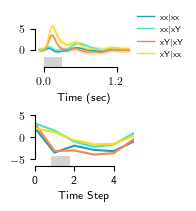

In [ ]:
# context
# Create a figure and axis
fig, axs = plt.subplots(2, 1, figsize=(1.85,2.0), constrained_layout=True)

plot_labels = ['xx|xx', 'xx|xY', 'xY|xY', 'xY|xx']
colors = {'xx|xx': '#229eba',
          'xx|xY': '#48e5ca',
          'xY|xY': '#f4884d',
          'xY|xx': '#f2dd20'}
label_str = {'xx|xx': r'xx$\mid$xx', 'xx|xY': r'xx$\mid$xY', 'xY|xY': r'xY$\mid$xY', 'xY|xx': r'xY$\mid$xx'}

axs[0].plot(time_points, exp_xxxx_global_means, label=label_str['xx|xx'], color=colors['xx|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxx_global_means - exp_xxxx_global_sems, exp_xxxx_global_means + exp_xxxx_global_sems, alpha=0.2, color=colors['xx|xx'])
axs[0].plot(time_points, exp_xxxY_global_means, label=label_str['xx|xY'], color=colors['xx|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xxxY_global_means - exp_xxxY_global_sems, exp_xxxY_global_means + exp_xxxY_global_sems, alpha=0.2, color=colors['xx|xY'])
axs[0].plot(time_points, exp_xYxY_global_means, label=label_str['xY|xY'], color=colors['xY|xY'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxY_global_means - exp_xYxY_global_sems, exp_xYxY_global_means + exp_xYxY_global_sems, alpha=0.2, color=colors['xY|xY'])
axs[0].plot(time_points, exp_xYxx_global_means, label=label_str['xY|xx'], color=colors['xY|xx'], linewidth=1)
axs[0].fill_between(time_points, exp_xYxx_global_means - exp_xYxx_global_sems, exp_xYxx_global_means + exp_xYxx_global_sems, alpha=0.2, color=colors['xY|xx'])


axs[0].set_ylim([-4, 8])

soa = 0.6  # in sec
# add little gray boxes at 0, 0.6, 1.2, 1.8 above the axis line
for x in [0]:
    axs[0].add_patch(plt.Rectangle(
        (x * soa, axs[0].get_ylim()[0] + 0.0 * np.ptp(axs[0].get_ylim())),  # bottom just above axis
        0.3,  # width
        0.2 * np.ptp(axs[0].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[0].transData,
        clip_on=False
    ))

axs[0].set_xticks([0, 1.2])
axs[0].set_xlabel('Time (sec)', fontsize=8)

for i, idxes in enumerate([xxxx, xxxy, xyxy, xyxx]):
    logits = pred_readout_logits[5][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes[0]))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    axs[1].plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    axs[1].fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

axs[1].set_xlim(left=6, right=len(mean)-1)
axs[1].set_xticks([6, 8, 10])
axs[1].set_xticklabels([0, 2, 4])
axs[1].set_ylim([-6.5, 5])

# add little gray boxes at 2,4,6,8 above the axis line
for x in [7]:
    axs[1].add_patch(plt.Rectangle(
        (x - 0.2, axs[1].get_ylim()[0] + 0.0 * np.ptp(axs[1].get_ylim())),  # bottom just above axis
        1.0,  # width
        0.2 * np.ptp(axs[1].get_ylim()),  # height
        facecolor='lightgray',
        transform=axs[1].transData,
        clip_on=False
    ))

axs[1].set_xlabel('Time Step', fontsize=8)

axs[0].legend(fontsize=6, loc=(1.0, 0.1), frameon=False)

sns.despine(trim=True)

plt.savefig(os.path.join(savedir, 'oddballs_exp_vs_model_proj_global_oddball_readout.pdf'), bbox_inches='tight', transparent=True)

# Supplementary plots

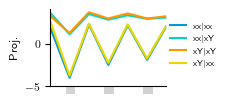

In [ ]:
# context projections from global oddball readout
# Create a figure and axis
fig, ax = plt.subplots(figsize=(1.5, 1))

plot_labels = ['xx|xx', 'xx|xY', 'xY|xY', 'xY|xx']
colors = {'xx|xx': '#009bd4',
          'xx|xY': '#00d4c5',
          'xY|xY': '#ff9600',
          'xY|xx': '#e9d900'}
label_str = {'xx|xx': r'xx$\mid$xx', 'xx|xY': r'xx$\mid$xY', 'xY|xY': r'xY$\mid$xY', 'xY|xx': r'xY$\mid$xx'}

for i, idxes in enumerate([xxxx, xxxy, xyxy, xyxx]):
    logits = pred_readout_logits[5][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes[0]))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    ax.plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    ax.fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

# Add labels and legend
ax.set_xlabel('Time Step', fontsize=8)
ax.set_ylabel('Proj.', fontsize=8)
ax.legend(fontsize=6, frameon=False, loc=(1.0,0.2))

# remove xticks/labels
ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylim(-5, 4)

# add little gray boxes at 2,4,6,8 below the axis line
for x in [1, 3, 5]:
    ax.add_patch(plt.Rectangle(
        (x - 0.2, ax.get_ylim()[0] - 0.1 * np.ptp(ax.get_ylim())),  # bottom just below axis
        0.5,  # width
        0.1 * np.ptp(ax.get_ylim()),  # height
        facecolor='lightgray',
        transform=ax.transData,
        clip_on=False
    ))

# set x limit to start from 7
ax.set_xlim(left=0, right=6)

sns.despine()

fig.savefig(os.path.join(savedir, 'oddballs_global_deviance_context_shared_encoding.pdf'), bbox_inches='tight', transparent=True)

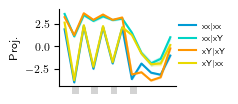

In [ ]:
# context projections from global oddball readout
# Create a figure and axis
fig, ax = plt.subplots(figsize=(1.5, 1.))

plot_labels = ['xx|xx', 'xx|xY', 'xY|xY', 'xY|xx']
colors = {'xx|xx': '#009bd4',
          'xx|xY': '#00d4c5',
          'xY|xY': '#ff9600',
          'xY|xx': '#e9d900'}
label_str = {'xx|xx': r'xx$\mid$xx', 'xx|xY': r'xx$\mid$xY', 'xY|xY': r'xY$\mid$xY', 'xY|xx': r'xY$\mid$xx'}

for i, idxes in enumerate([xxxx, xxxy, xyxy, xyxx]):
    logits = pred_readout_logits[5][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes[0]))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    ax.plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    ax.fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

# Add labels and legend
ax.set_xlabel('Time Step', fontsize=8)
ax.set_ylabel('Proj.', fontsize=8)
ax.legend(fontsize=6, frameon=False, loc=(1.0,0.2))

ax.set_xticks([])
ax.set_xlabel('')

# add little gray boxes at 2,4,6,8 below the axis line
for x in [1, 3, 5, 7]:
    ax.add_patch(plt.Rectangle(
        (x - 0.2, ax.get_ylim()[0] - 0.1 * np.ptp(ax.get_ylim())),  # bottom just below axis
        0.7,  # width
        0.1 * np.ptp(ax.get_ylim()),  # height
        facecolor='lightgray',
        transform=ax.transData,
        clip_on=False
    ))

sns.despine()

fig.savefig(os.path.join(savedir, 'oddballs_global_deviance_context_shared_encoding_full.pdf'), bbox_inches='tight', transparent=True)

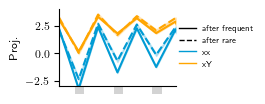

In [ ]:
from matplotlib.lines import Line2D

# context projections for xx and xy after frequent/rare
# Create a figure and axis
fig, ax = plt.subplots(figsize=(1.5, 1.))

plot_labels = ['xx', 'xY']
colors = {'xY': 'orange',
          'xx': '#009bd4'}
label_str = {'xx': r'xx', 'xY': r'xY'}

for i, idxes in enumerate([torch.where(xx_after_frequent)[0], torch.where(xy_after_frequent)[0]]):
    logits = pred_readout_logits[5][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    ax.plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]])
    ax.fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

for i, idxes in enumerate([torch.where(xx_after_rare)[0], torch.where(xy_after_rare)[0]]):
    logits = pred_readout_logits[5][idxes]
    logits_diff = logits
    mean = logits_diff.mean(0).detach().cpu().numpy().squeeze()
    stds = logits_diff.std(0).detach().cpu().numpy().squeeze() / np.sqrt(len(idxes))

    # roll last element to front for better visualization
    mean = np.roll(mean, 1)
    stds = np.roll(stds, 1)
    ax.plot(mean, label=label_str[plot_labels[i]], color=colors[plot_labels[i]], linestyle='dashed')
    ax.fill_between(np.arange(len(mean)), mean - stds, mean + stds, alpha=0.2, color=colors[plot_labels[i]])

# Add labels and legend
ax.set_xlabel('Time Step', fontsize=8)
ax.set_ylabel('Proj.', fontsize=8)
# Create custom legend with xx and xY text in corresponding colors, showing black solid/dashed lines for frequent/rare
legend_elements = [
    Line2D([0], [0], color='black', lw=1, label='after frequent', linestyle='solid'),
    Line2D([0], [0], color='black', lw=1, label='after rare', linestyle='dashed'),
    Line2D([0], [0], color=colors['xx'], lw=1, label='xx'),
    Line2D([0], [0], color=colors['xY'], lw=1, label='xY'),
]
ax.legend(handles=legend_elements, fontsize=6, frameon=False, loc=(1.0,0.2))

ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylim(bottom=-3, top=4)

# add little gray boxes at 2,4,6,8 below the axis line
for x in [1, 3, 5]:
    ax.add_patch(plt.Rectangle(
        (x - 0.2, ax.get_ylim()[0] - 0.1 * np.ptp(ax.get_ylim())),  # bottom just below axis
        0.5,  # width
        0.1 * np.ptp(ax.get_ylim()),  # height
        facecolor='lightgray',
        transform=ax.transData,
        clip_on=False
    ))

# set x limit to start from 7
ax.set_xlim(left=0, right=6)

sns.despine()

fig.savefig(os.path.join(savedir, 'oddballs_global_context_frequent_vs_rare.pdf'), bbox_inches='tight', transparent=True)